In [6]:
%%writefile bus_utils.py
import os
import glob
import random
import numpy as np
import pandas as pd
import cv2
import torch
from scipy import ndimage
from torch.utils.data import Dataset

ROOT = "/kaggle/input"
DATASETS = ["BUSI", "BUS-BRA", "BUS-UCLM", "BrEaST"]
IMAGE_SIZE = 512
CLIP_PERCENTILES = (1, 99)

_TAIL_INDEX = None


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def find_file(pattern, root=ROOT):
    hits = sorted(glob.glob(os.path.join(root, "**", pattern), recursive=True))
    return hits[0] if hits else None


def _tail(path, n=3):
    return "/".join(str(path).replace("\\", "/").split("/")[-n:])


def resolve(path):
    global _TAIL_INDEX
    if not path or path == "nan":
        return ""
    if os.path.exists(path):
        return path
    if _TAIL_INDEX is None:
        _TAIL_INDEX = {_tail(p): p for p in glob.glob(os.path.join(ROOT, "**", "*.png"), recursive=True)}
    found = _TAIL_INDEX.get(_tail(path))
    if found is None:
        raise FileNotFoundError(path)
    return found


def load_splits(keep_only=True):
    df = pd.read_csv(find_file("splits.csv"), dtype={"device": str, "mask_alt": str})
    for col in ["mask_clean", "mask_alt", "flag", "exclude", "duplicate_of", "device"]:
        df[col] = df[col].fillna("").astype(str).replace({"nan": ""})
    if keep_only:
        df = df[df.keep].reset_index(drop=True)
    df["image"] = df.image.map(resolve)
    df["mask_clean"] = df.mask_clean.map(resolve)
    df["mask_alt"] = df.mask_alt.map(lambda p: resolve(p) if p else "")
    return df


def read_image(path):
    return cv2.imread(path, cv2.IMREAD_GRAYSCALE)


def read_mask(path):
    return (cv2.imread(path, cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)


def normalise(img):
    lo, hi = np.percentile(img, CLIP_PERCENTILES)
    x = np.clip(img.astype(np.float32), lo, hi)
    return (x - x.mean()) / (x.std() + 1e-6)


def pad_square(x, value=0):
    h, w = x.shape[:2]
    side = max(h, w)
    top, left = (side - h) // 2, (side - w) // 2
    out = np.full((side, side), value, dtype=x.dtype)
    out[top:top + h, left:left + w] = x
    return out, (top, left, h, w)


def preprocess(img, mask=None, size=IMAGE_SIZE):
    x, meta = pad_square(normalise(img))
    x = cv2.resize(x, (size, size), interpolation=cv2.INTER_AREA)
    if mask is None:
        return x, None, meta
    m, _ = pad_square(mask)
    m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
    return x, m, meta


def to_original(pred, meta):
    top, left, h, w = meta
    side = max(h, w)
    full = cv2.resize(pred.astype(np.float32), (side, side), interpolation=cv2.INTER_LINEAR)
    return full[top:top + h, left:left + w]


def train_augment():
    import albumentations as A
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05), rotate=(-10, 10), p=0.5),
    ])


class BUSDataset(Dataset):
    def __init__(self, frame, with_mask=True, augment=None, size=IMAGE_SIZE, mask_column="mask_clean"):
        self.frame = frame.reset_index(drop=True)
        self.with_mask = with_mask
        self.augment = augment
        self.size = size
        self.mask_column = mask_column

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        img = read_image(row.image)
        mask = read_mask(row[self.mask_column]) if self.with_mask else None
        x, m, meta = preprocess(img, mask, self.size)
        if self.augment is not None and m is not None:
            out = self.augment(image=x, mask=m)
            x, m = out["image"], out["mask"]
        item = {"image": torch.from_numpy(x[None].astype(np.float32)), "index": i,
                "meta": torch.tensor(meta)}
        if m is not None:
            item["mask"] = torch.from_numpy(m[None].astype(np.float32))
        return item


class ImageOnly:
    def __init__(self, frame):
        self.frame = frame.drop(columns=[c for c in frame.columns if c.startswith("mask")])

    def dataset(self, size=IMAGE_SIZE):
        return BUSDataset(self.frame, with_mask=False, size=size)


def select(df, dataset, folds=None, roles=None):
    sel = df.dataset == dataset
    if folds is not None:
        sel &= df.fold.isin(list(folds))
    if roles is not None:
        sel &= df.role.isin(list(roles))
    return df[sel].reset_index(drop=True)


def target_split(df, target, test_fold):
    data = df[(df.dataset == target) & df.role.isin(["pool", "train", "val"])]
    test = data[data.fold == test_fold].reset_index(drop=True)
    support_pool = data[data.fold != test_fold].reset_index(drop=True)
    return support_pool, test


def check_no_test(frame, test):
    leaked = set(frame.patient) & set(test.patient)
    if leaked:
        raise RuntimeError(f"{len(leaked)} test patients reached a fix")


def draw_support(pool, k, draw, seed=2026):
    key = sum(ord(c) for c in pool.dataset.iloc[0])
    rng = np.random.default_rng([seed, k, draw, key])
    shuffled = pool.sample(frac=1, random_state=int(rng.integers(1 << 31)))
    picked = shuffled.drop_duplicates("patient").head(k)
    if len(picked) < k:
        picked = pd.concat([picked, shuffled.drop(picked.index).head(k - len(picked))])
    return picked.reset_index(drop=True)


def equivalent_diameter(mask):
    return 2.0 * np.sqrt(mask.sum() / np.pi)


def _surface(mask):
    m = mask.astype(bool)
    if not m.any():
        return m
    return m & ~ndimage.binary_erosion(m, border_value=0)


def _surface_distances(a, b, spacing=1.0):
    sa, sb = _surface(a), _surface(b)
    dt_b = ndimage.distance_transform_edt(~sb, sampling=spacing)
    dt_a = ndimage.distance_transform_edt(~sa, sampling=spacing)
    return dt_b[sa], dt_a[sb]


def dice(pred, gt):
    p, g = pred.astype(bool), gt.astype(bool)
    s = p.sum() + g.sum()
    return 1.0 if s == 0 else 2.0 * (p & g).sum() / s


def iou(pred, gt):
    p, g = pred.astype(bool), gt.astype(bool)
    u = (p | g).sum()
    return 1.0 if u == 0 else (p & g).sum() / u


def hd95(pred, gt, spacing=1.0):
    p, g = pred.astype(bool), gt.astype(bool)
    if not p.any() and not g.any():
        return 0.0
    if not p.any() or not g.any():
        return float(np.hypot(*gt.shape) * spacing)
    d_pg, d_gp = _surface_distances(p, g, spacing)
    return float(np.percentile(np.concatenate([d_pg, d_gp]), 95))


def nsd(pred, gt, tolerance, spacing=1.0):
    p, g = pred.astype(bool), gt.astype(bool)
    if not p.any() and not g.any():
        return 1.0
    if not p.any() or not g.any():
        return 0.0
    d_pg, d_gp = _surface_distances(p, g, spacing)
    return float(((d_pg <= tolerance).sum() + (d_gp <= tolerance).sum()) / (len(d_pg) + len(d_gp)))


def signed_area_error(pred, gt):
    g = gt.sum()
    return float((pred.sum() - g) / g) if g else float(pred.sum() > 0)


def evaluate(pred, gt, tolerance_frac=0.05, spacing=1.0):
    tolerance = tolerance_frac * max(equivalent_diameter(gt), 1.0) * spacing
    return {
        "dice": dice(pred, gt),
        "iou": iou(pred, gt),
        "nsd": nsd(pred, gt, tolerance, spacing),
        "hd95": hd95(pred, gt, spacing),
        "area_error": signed_area_error(pred, gt),
        "pred_empty": bool(not pred.any()),
    }

Overwriting bus_utils.py


In [7]:
import os
base = "/kaggle/input/datasets/tanjilbinmohiuddin"
print(sorted(os.listdir(base)) if os.path.exists(base) else os.listdir("/kaggle/input"))

['breast-lesions-usg', 'bus-clean-v1', 'bus-uclm', 'busi-bra-j35', 'busi-ds', 'busi-duplicate-list']


**load the splits**

In [8]:
import json
import time
import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from IPython.display import display
from bus_utils import *

set_seed(2026)
df = load_splits()
display(pd.crosstab(df.dataset, df.role))

role,conf,dev,pool,train,val
dataset,,,,,
BUS-BRA,377,373,0,940,185
BUS-UCLM,0,0,264,0,0
BUSI,0,0,466,0,0
BrEaST,0,0,252,0,0


check the metrics on known shapes

In [9]:
yy, xx = np.mgrid[:200, :200]
circle = lambda cx, cy, r: ((xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2).astype(np.uint8)
a, b, empty = circle(100, 100, 40), circle(104, 100, 40), np.zeros((200, 200), np.uint8)

checks = {
    "dice_identical": dice(a, a) == 1.0,
    "dice_shift_4px": 0.9 < dice(a, b) < 0.97,
    "dice_both_empty": dice(empty, empty) == 1.0,
    "dice_one_empty": dice(empty, a) == 0.0,
    "hd95_shift_4px": 3.0 <= hd95(a, b) <= 4.5,
    "hd95_one_empty": hd95(empty, a) > 200,
    "nsd_within_tolerance": nsd(a, b, tolerance=5) == 1.0,
    "nsd_outside_tolerance": nsd(a, b, tolerance=1) < 0.6,
    "area_error_bigger": signed_area_error(circle(100, 100, 44), a) > 0.15,
    "equivalent_diameter": abs(equivalent_diameter(a) - 80) < 2,
}
assert all(checks.values()), {k: v for k, v in checks.items() if not v}
display(pd.Series(checks))

dice_identical           True
dice_shift_4px           True
dice_both_empty          True
dice_one_empty           True
hd95_shift_4px           True
hd95_one_empty           True
nsd_within_tolerance     True
nsd_outside_tolerance    True
area_error_bigger        True
equivalent_diameter      True
dtype: bool

resize round-trip check

In [10]:
rows = df.groupby("dataset").sample(n=60, random_state=0)
roundtrip = []
for row in rows.itertuples():
    mask = read_mask(row.mask_clean)
    _, m, meta = preprocess(read_image(row.image), mask)
    back = to_original(m, meta) > 0.5
    roundtrip.append({"dataset": row.dataset, "dice": dice(back, mask)})
roundtrip = pd.DataFrame(roundtrip)
display(roundtrip.groupby("dataset").dice.describe()[["min", "50%", "mean"]].round(4))
assert roundtrip.dice.median() > 0.97

,min,50%,mean
dataset,,,
BUS-BRA,0.9798,0.9927,0.9921
BUS-UCLM,0.9647,0.9901,0.9880
BUSI,0.9566,0.9895,0.9876
BrEaST,0.9728,0.9901,0.9878


data loader check

In [11]:
loader = DataLoader(BUSDataset(df.sample(64, random_state=0), augment=train_augment()),
                    batch_size=16, num_workers=2, shuffle=True)
start = time.time()
for batch in loader:
    pass
seconds_per_image = (time.time() - start) / 64
x, y = batch["image"], batch["mask"]
assert x.shape[1:] == (1, IMAGE_SIZE, IMAGE_SIZE) and y.shape == x.shape
assert set(torch.unique(y).tolist()) <= {0.0, 1.0}
display(pd.Series({"batch_shape": tuple(x.shape), "mean": round(x.mean().item(), 3),
                   "std": round(x.std().item(), 3), "seconds_per_image": round(seconds_per_image, 4)}))

batch_shape          (16, 1, 512, 512)
mean                             0.002
std                               0.85
seconds_per_image               0.1253
dtype: object

no-leak rule and support draws

In [12]:
pool, test = target_split(df, "BrEaST", test_fold=0)
support = draw_support(pool, k=20, draw=0)
check_no_test(support, test)
check_no_test(ImageOnly(pool).frame, test)
assert len(support) == 20 and support.patient.is_unique
assert not any(c.startswith("mask") for c in ImageOnly(pool).frame.columns)
assert draw_support(pool, 20, 0).case.tolist() == support.case.tolist()
assert draw_support(pool, 20, 1).case.tolist() != support.case.tolist()
try:
    check_no_test(pd.concat([support, test.head(1)]), test)
    leak_caught = False
except RuntimeError:
    leak_caught = True
assert leak_caught
assert select(df, "BUS-BRA", roles=["dev", "conf"]).fold.eq(-1).all()
display(pd.Series({"support": len(support), "pool": len(pool), "test": len(test), "leak_caught": leak_caught}))

support          20
pool            202
test             50
leak_caught    True
dtype: object

what the model will see

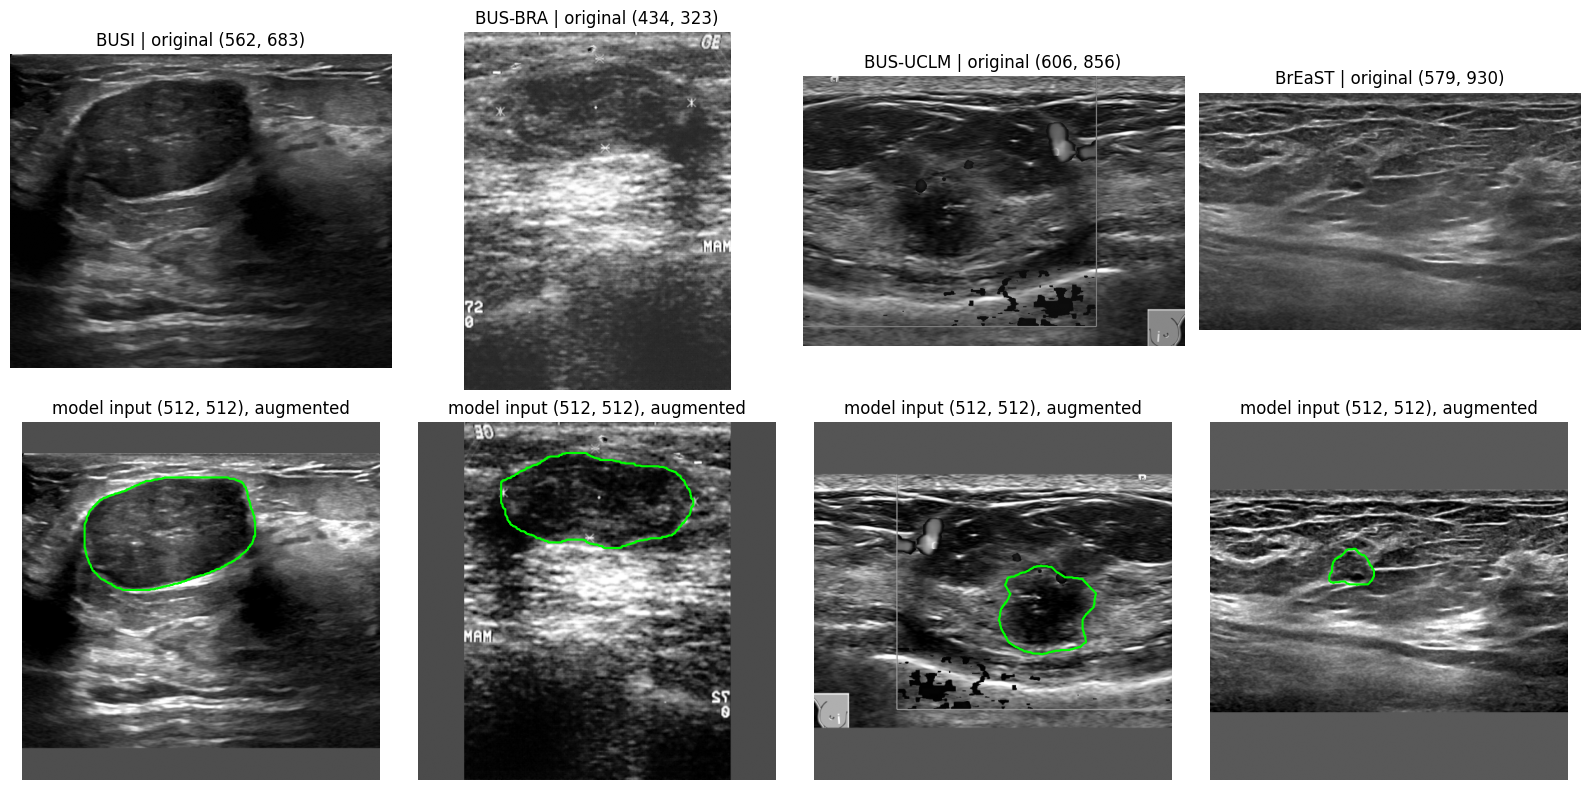

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, name in enumerate(DATASETS):
    row = df[df.dataset == name].sample(1, random_state=3).iloc[0]
    item = BUSDataset(pd.DataFrame([row]), augment=train_augment())[0]
    x, m = item["image"][0].numpy(), item["mask"][0].numpy()
    axes[0, col].imshow(read_image(row.image), cmap="gray")
    axes[0, col].set_title(f"{name} | original {read_image(row.image).shape}")
    axes[1, col].imshow(x, cmap="gray")
    axes[1, col].contour(m, levels=[0.5], colors="lime", linewidths=1.5)
    axes[1, col].set_title(f"model input {x.shape}, augmented")
    for ax in axes[:, col]:
        ax.axis("off")
fig.tight_layout()
fig.savefig("/kaggle/working/s3_preprocessing.png", bbox_inches="tight")
plt.show()

save the check report

In [14]:
report = {"metric_checks": bool(all(checks.values())),
          "roundtrip_dice_median": float(roundtrip.dice.median()),
          "roundtrip_dice_min": float(roundtrip.dice.min()),
          "seconds_per_image": float(seconds_per_image),
          "n_images": int(len(df)), "image_size": IMAGE_SIZE}
with open("/kaggle/working/s3_checks.json", "w") as f:
    json.dump(report, f, indent=2)
display(pd.Series(report))

metric_checks                True
roundtrip_dice_median    0.990574
roundtrip_dice_min       0.956589
seconds_per_image        0.125325
n_images                     2857
image_size                    512
dtype: object

In [15]:
import glob
print(glob.glob("/kaggle/input/**/splits.csv", recursive=True))

['/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1/splits.csv']


In [16]:
import glob
print(glob.glob("/kaggle/input/**/splits.csv", recursive=True))

['/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1/splits.csv']


In [17]:
import glob, os

manifest = glob.glob("/kaggle/input/**/manifest.json", recursive=True)
print(manifest)

folder = os.path.dirname(manifest[0])
print(sorted(os.listdir(folder)))
print([f for f in glob.glob(folder + "/*") if f.endswith(".csv")])

['/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1/manifest.json']
['busi_duplicate_pairs.csv', 'manifest.json', 'masks', 'splits.csv']
['/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1/busi_duplicate_pairs.csv', '/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1/splits.csv']


In [18]:
import pandas as pd, glob

s = pd.read_csv(glob.glob("/kaggle/input/**/splits.csv", recursive=True)[0])
for name, g in s.groupby("dataset"):
    print(name, "->", g.image.iloc[0])

BUS-BRA -> /kaggle/input/datasets/tanjilbinmohiuddin/busi-bra-j35/BUSBRA/Images/bus_0001-l.png
BUS-UCLM -> /kaggle/input/datasets/tanjilbinmohiuddin/bus-uclm/BUS-UCLM Breast ultrasound lesion segmentation dataset/BUS-UCLM/images/ALWI_000.png
BUSI -> /kaggle/input/datasets/tanjilbinmohiuddin/busi-ds/Dataset_BUSI_with_GT/benign/benign (1).png
BrEaST -> /kaggle/input/datasets/tanjilbinmohiuddin/breast-lesions-usg/BrEaST-Lesions_USG-images_and_masks-Dec-15-2023/BrEaST-Lesions_USG-images_and_masks/case001.png


In [19]:
import os, glob

print(glob.glob("/kaggle/input/**/splits.csv", recursive=True))

base = "/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1"
print(os.path.exists(base))
if os.path.exists(base):
    print(sorted(os.listdir(base)))

['/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1/splits.csv']
True
['busi_duplicate_pairs.csv', 'manifest.json', 'masks', 'splits.csv']


In [20]:
import os, glob

base = "/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1"
print(sorted(os.listdir(base)))
print("png count:", len(glob.glob(base + "/**/*.png", recursive=True)))
print("splits.csv:", glob.glob(base + "/**/splits.csv", recursive=True))

['busi_duplicate_pairs.csv', 'manifest.json', 'masks', 'splits.csv']
png count: 2857
splits.csv: ['/kaggle/input/datasets/tanjilbinmohiuddin/bus-clean-v1/splits.csv']


**Fake Shifting
**

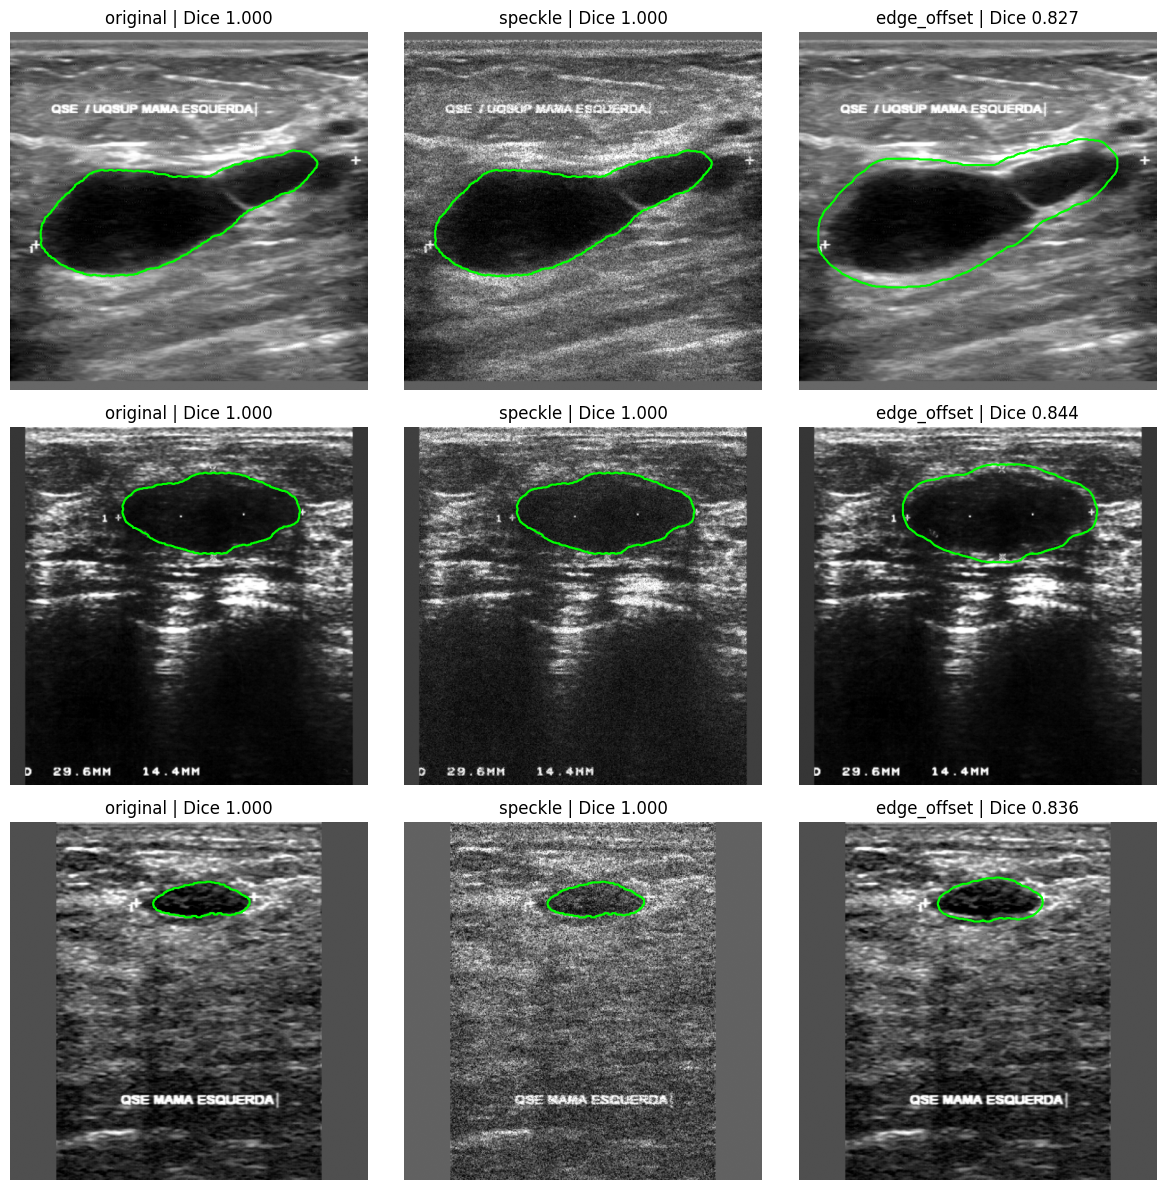

In [21]:
import sys, glob
import matplotlib.pyplot as plt

found = glob.glob("/kaggle/input/**/fake_shifts.py", recursive=True)
assert found, "bus-shifts-v1 add koro, tarpor restart koro"
sys.path.append(found[0].rsplit("/", 1)[0])
from fake_shifts import IMAGE_SHIFTS, MASK_SHIFTS


class ShiftedDataset(BUSDataset):
    def __init__(self, frame, image_shift=None, mask_shift=None, strength=0.5, seed=2026, **kwargs):
        super().__init__(frame, **kwargs)
        self.image_shift = image_shift
        self.mask_shift = mask_shift
        self.strength = strength
        self.seed = seed

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        img = read_image(row.image)
        mask = read_mask(row[self.mask_column])
        if self.image_shift is not None:
            raw = img.astype(np.float32) / 255.0
            img = IMAGE_SHIFTS[self.image_shift](raw, self.strength, self.seed + i).astype(np.float32)
        x, m, meta = preprocess(img, mask, self.size)
        if self.mask_shift is not None and m.any():
            m = MASK_SHIFTS[self.mask_shift](m.astype(bool), self.strength, self.seed + i).astype(np.uint8)
        return {
            "image": torch.from_numpy(x[None].astype(np.float32)),
            "mask": torch.from_numpy(m[None].astype(np.float32)),
            "index": i,
            "meta": torch.tensor(meta),
        }


dev = select(df, "BUS-BRA", roles=["dev"])
rows = dev.sample(3, random_state=0)
variants = [("original", None, None), ("speckle", "speckle", None), ("edge_offset", None, "edge_offset")]

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for r in range(3):
    base_mask = ShiftedDataset(rows.iloc[[r]])[0]["mask"][0].numpy()
    for c, (title, img_shift, msk_shift) in enumerate(variants):
        item = ShiftedDataset(rows.iloc[[r]], image_shift=img_shift, mask_shift=msk_shift, strength=0.5)[0]
        x, m = item["image"][0].numpy(), item["mask"][0].numpy()
        axes[r, c].imshow(x, cmap="gray")
        axes[r, c].contour(m, levels=[0.5], colors="lime", linewidths=1.5)
        axes[r, c].set_title(f"{title} | Dice {dice(base_mask, m):.3f}")
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()